<a href="https://colab.research.google.com/github/IRay3477/Pengembangan-Model-Deep-Learning-dan-Implementasi-API/blob/main/Deep_Learning_Peringkasan_Otomatis_Video_Kuliah_Bahasa_Indonesia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tahap 1: Profiling dataset + uji terjemahan

In [ ]:
!pip -q install transformers sentencepiece sacremoses

import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

# Semua path diatur di sini, kalau folder pindah cukup ubah folder_utama
folder_utama = '/content/drive/MyDrive/DEEP_LEARNING_test'
csv_path = f'{folder_utama}/Dataset/ak_lectures_summarized.csv'
output_tahap1 = f'{folder_utama}/tahap1'
output_tahap2 = f'{folder_utama}/tahap2'
os.makedirs(output_tahap1, exist_ok=True)
os.makedirs(output_tahap2, exist_ok=True)

Mounted at /content/drive


## 1. Load data

In [ ]:
df = pd.read_csv(csv_path)
print('Ukuran data:', df.shape)

print('=' * 30)
print('Tipe data tiap kolom')
print('=' * 30)
print(df.dtypes)

df.head(3)

Ukuran data: (1871, 7)
Tipe data tiap kolom
Unnamed: 0             int64
Course Name           object
Chapter               object
Video Name            object
Youtube Video Link    object
Summary               object
Transcript            object
dtype: object


,Unnamed: 0,Course Name,Chapter,Video Name,Youtube Video Link,Summary,Transcript
0,0,Biology,Immune System,Introduction to Immune System,https://www.youtube.com/embed/bW-eEBxJYaM?enab...,Instead of being localized at a specific organ...,"Unlike most other systems of our body, the im..."
1,1,Biology,Immune System,Leukocytes of Immune System,https://www.youtube.com/embed/ZQSzIOMRZMQ?enab...,"Leukocytes, or white blood cells, are the cell...","Lucocytes, also known as white blood cells, a..."
2,2,Biology,Immune System,Innate (Non-specific) Immune System,https://www.youtube.com/embed/os1oh8AprYw?enab...,Our innate immune system consists of non-speci...,Our immune system consists of two divisions. ...


## 2. Pilih kolom

Variabel di bawah hanya menyimpan **nama kolom** (string), supaya nama kolom tidak diketik berulang-ulang. Jadi `df[kolom_transkrip]` sama persis dengan `df['Transcript']`.

- `kolom_transkrip` → input model (teks yang akan diringkas)
- `kolom_ringkasan` → target/label (ringkasan referensi)
- `kolom_video` → penanda unik tiap video, untuk cek apakah ada video yang muncul lebih dari sekali

In [ ]:
kolom_transkrip = 'Transcript'
kolom_ringkasan = 'Summary'
kolom_video = 'Youtube Video Link'

# 'Unnamed: 0' cuma nomor index lama yang ikut tersimpan di CSV
df = df.drop(columns=['Unnamed: 0'])

print('Video unik:', df[kolom_video].nunique(), 'dari', len(df), 'baris')
print('\nJumlah video per course:')
print(df['Course Name'].value_counts())

Video unik: 1871 dari 1871 baris

Jumlah video per course:
Course Name
Classical physics    638
Organic chemistry    318
Biochemistry         293
Biology              250
Modern physics       232
General chemistry    140
Name: count, dtype: int64


## 3. Kualitas data

### 3.1 Jumlah nilai kosong
Dicek dua jenis kosong: `NaN` (sel benar-benar kosong) dan string yang isinya hanya spasi.

In [ ]:
print('NaN per kolom:')
print(df.isna().sum())

print('\nDetail kolom teks:')
for kolom in [kolom_transkrip, kolom_ringkasan]:
    jumlah_nan = df[kolom].isna().sum()
    jumlah_spasi = (df[kolom].notna() & (df[kolom].str.strip() == '')).sum()
    print(f'{kolom}: NaN = {jumlah_nan}, hanya spasi = {jumlah_spasi}')

NaN per kolom:
Course Name            0
Chapter                0
Video Name             0
Youtube Video Link     0
Summary               12
Transcript            17
dtype: int64

Detail kolom teks:
Transcript: NaN = 17, hanya spasi = 0
Summary: NaN = 12, hanya spasi = 0


### 3.2 Contoh baris dengan transkrip kosong

In [ ]:
transkrip_kosong = df[df[kolom_transkrip].isna()]
print('Jumlah baris transkrip kosong:', len(transkrip_kosong))
transkrip_kosong[['Course Name', 'Chapter', 'Video Name', kolom_transkrip, kolom_ringkasan]].head(10)

Jumlah baris transkrip kosong: 17


,Course Name,Chapter,Video Name,Transcript,Summary
20,Biology,Immune System,Autoimmunity,NaN,Our immune system displays a natural immunolog...
94,Biology,Genetics,DNA Replication: Helicase and Unwinding,NaN,"Before DNA replication actually begins, a spec..."
95,Biology,Genetics,DNA Replication: Leading and Lagging Strand,NaN,Once DNA helicase binds to the origin of repli...
101,Biology,Genetics,Translation: Ribosomes and Initiation,NaN,Ribosomes are the machinery of biological cell...
102,Biology,Genetics,Translation: Elongation and Termination,NaN,"Following initiation, the ribosome moves on to..."
423,Organic chemistry,Alkenes and Alkynes,Cis-Trans/Z-E Isomer Stability,NaN,Cis or Z isomers are less stable and higher in...
463,Organic chemistry,Substitution and Elimination Reactions,Alkylation: Application of Sn2,NaN,"In this lecture, I discuss a biochemical appli..."
471,Organic chemistry,Substitution and Elimination Reactions,"E1 Reaction: Elimination, Unimolecular",NaN,"In this lecture, I go over the Elimination, Un..."
474,Organic chemistry,Substitution and Elimination Reactions,"E2 Reaction: Elimination, Bimolecular",NaN,"In this lecture, I discuss the E2 reaction and..."
816,Biochemistry,Enzymes,Catalytic Efficiency of Enzymes (kcat/Km),NaN,One way to measure the catalytic efficiency of...


### 3.3 Contoh baris dengan ringkasan kosong

In [ ]:
ringkasan_kosong = df[df[kolom_ringkasan].isna()]
print('Jumlah baris ringkasan kosong:', len(ringkasan_kosong))
ringkasan_kosong[['Course Name', 'Chapter', 'Video Name', kolom_transkrip, kolom_ringkasan]].head(10)

Jumlah baris ringkasan kosong: 12


,Course Name,Chapter,Video Name,Transcript,Summary
493,Organic chemistry,Addition Reactions,Dimerization and Polymerization,So let's recall what a hydrohalgenation react...,NaN
989,Biochemistry,Amino Acid Metabolism,Proteasome complex,So once we attach many ubiquitin molecules on...,NaN
990,Biochemistry,Amino Acid Metabolism,Deamination of Amino Acids,Once proteins are broken down into their indi...,NaN
991,Biochemistry,Amino Acid Metabolism,Glucose-alanine cycle,Although our liver is responsible for the maj...,NaN
992,Biochemistry,Amino Acid Metabolism,Urea cycle,So at last let's discuss the urea cycle. So w...,NaN
993,Biochemistry,Amino Acid Metabolism,Defects in Urea Cycle and Hyperammonemia,"Whenever our cells break down amino acids, th...",NaN
994,Biochemistry,Amino Acid Metabolism,Introduction to glucogenic and ketogenic amino...,When we break down amino acids inside our liv...,NaN
995,Biochemistry,Amino Acid Metabolism,Metabolism of Amino Acids to Pyruvate,6. Adet wantumino acids can readily be metabo...,NaN
996,Biochemistry,Amino Acid Metabolism,Metabolism of Amino Acids to Ketoglutarate,"Previously, we saw how we can transform six o...",NaN
997,Biochemistry,Amino Acid Metabolism,Metabolism of Methionine,"Three of the 21 amino acids, namely valine, m...",NaN


### 3.4 Apakah ada baris yang kosong di dua kolom sekaligus?

In [ ]:
pd.crosstab(df[kolom_transkrip].isna(), df[kolom_ringkasan].isna(),
            rownames=['transkrip kosong'], colnames=['ringkasan kosong'])

ringkasan kosong,False,True
transkrip kosong,,
False,1842,12
True,17,0


### 3.5 Duplikat transkrip

Hanya dicek pada baris yang **tidak kosong**. Kalau baris kosong ikut dihitung, semua sel kosong dianggap "sama" sehingga jumlah duplikat jadi terlihat lebih besar dari aslinya.

In [ ]:
transkrip_terisi = df[df[kolom_transkrip].notna()]
duplikat_transkrip = transkrip_terisi[transkrip_terisi[kolom_transkrip].str.strip().duplicated(keep=False)]

print('Baris dengan transkrip duplikat:', len(duplikat_transkrip))
duplikat_transkrip.sort_values(kolom_transkrip)[['Course Name', 'Chapter', 'Video Name', kolom_video]].head(20)

Baris dengan transkrip duplikat: 0


,Course Name,Chapter,Video Name,Youtube Video Link


### 3.6 Duplikat ringkasan

Baris dengan ringkasan yang sama diberi `nomor_grup` yang sama. Karena transkripnya berbeda (lihat 3.5), ringkasan yang sama berarti minimal satu baris di grup itu labelnya tidak cocok dengan transkripnya.

In [ ]:
ringkasan_terisi = df[df[kolom_ringkasan].notna()].copy()
ringkasan_terisi['ringkasan_rapi'] = ringkasan_terisi[kolom_ringkasan].str.strip()

duplikat_ringkasan = ringkasan_terisi[ringkasan_terisi['ringkasan_rapi'].duplicated(keep=False)].copy()
duplikat_ringkasan['nomor_grup'] = duplikat_ringkasan.groupby('ringkasan_rapi').ngroup()
duplikat_ringkasan['awal_ringkasan'] = duplikat_ringkasan[kolom_ringkasan].str[:80] + '...'

print('Baris dengan ringkasan duplikat:', len(duplikat_ringkasan))
print('Jumlah grup ringkasan yang sama:', duplikat_ringkasan['nomor_grup'].nunique())
duplikat_ringkasan.sort_values('nomor_grup')[['nomor_grup', 'Course Name', 'Chapter', 'Video Name', 'awal_ringkasan']].head(20)

Baris dengan ringkasan duplikat: 96
Jumlah grup ringkasan yang sama: 48


,nomor_grup,Course Name,Chapter,Video Name,awal_ringkasan
136,0,Biology,Genetics,Aneuploidy and Nondisjunction (Part II),A karyotype is a pictorial representation of a...
135,0,Biology,Genetics,Aneuploidy and Nondisjunction,A karyotype is a pictorial representation of a...
385,1,General chemistry,Electrochemistry,Neuron Cells (Part I),"A neuron, also called a nerve cell, is a speci..."
386,1,General chemistry,Electrochemistry,Neuron Cells (Part II),"A neuron, also called a nerve cell, is a speci..."
134,2,Biology,Genetics,Pedigree Analysis for Autosomal Dominant Trait...,A third mode of inheritance is called autosoma...
133,2,Biology,Genetics,Pedigree Analysis for Autosomal Dominant Traits,A third mode of inheritance is called autosoma...
18,3,Biology,Immune System,ABO Blood Types (Part II),Another important group of antigens that can a...
19,3,Biology,Immune System,Rh Factor and Rh Incompatibility,Another important group of antigens that can a...
841,4,Biochemistry,Enzymes,Covalent Modification and Phosphorylation,Another method by which our cells regulate the...
842,4,Biochemistry,Enzymes,Covalent Modification and Phosphorylation (Par...,Another method by which our cells regulate the...


### 3.7 Duplikat pasangan (transkrip + ringkasan sama persis)

In [ ]:
data_terisi = df.dropna(subset=[kolom_transkrip, kolom_ringkasan])
jumlah_duplikat_pasangan = data_terisi.duplicated([kolom_transkrip, kolom_ringkasan]).sum()
print('Duplikat pasangan:', jumlah_duplikat_pasangan)

Duplikat pasangan: 0


## 4. Statistik panjang (kata & token) + rasio kompresi

Token dihitung pakai tokenizer mT5 karena itu kandidat model; batas input model ±512 token.
Catatan: ini masih teks **bahasa Inggris**. Setelah diterjemahkan, jumlah token biasanya bertambah, jadi perlu dihitung ulang.

In [ ]:
from transformers import AutoTokenizer
tokenizer_mt5 = AutoTokenizer.from_pretrained('google/mt5-small')

data_panjang = df.dropna(subset=[kolom_transkrip, kolom_ringkasan]).copy()
data_panjang['kata_transkrip'] = data_panjang[kolom_transkrip].str.split().str.len()
data_panjang['kata_ringkasan'] = data_panjang[kolom_ringkasan].str.split().str.len()

token_transkrip = tokenizer_mt5(data_panjang[kolom_transkrip].tolist(), add_special_tokens=False)['input_ids']
token_ringkasan = tokenizer_mt5(data_panjang[kolom_ringkasan].tolist(), add_special_tokens=False)['input_ids']
data_panjang['token_transkrip'] = [len(ids) for ids in token_transkrip]
data_panjang['token_ringkasan'] = [len(ids) for ids in token_ringkasan]

data_panjang['kompresi_kata'] = data_panjang['kata_ringkasan'] / data_panjang['kata_transkrip']

kolom_statistik = ['kata_transkrip', 'token_transkrip', 'kata_ringkasan', 'token_ringkasan', 'kompresi_kata']
statistik = data_panjang[kolom_statistik].describe(percentiles=[.25, .5, .75, .95]).T.round(2)
print(statistik)
print(f"\nTranskrip > 512 token: {(data_panjang['token_transkrip'] > 512).mean() * 100:.1f}%")

statistik.to_csv(f'{output_tahap1}/profiling_stats.csv')

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

                  count     mean     std   min      25%      50%      75%  \
kata_transkrip   1842.0  1081.64  478.70  48.0   725.25  1005.50  1367.00   
token_transkrip  1842.0  1578.84  726.88  67.0  1040.25  1435.00  2002.00   
kata_ringkasan   1842.0   144.71   82.11   1.0    84.00   128.00   190.00   
token_ringkasan  1842.0   220.84  130.99   1.0   126.00   190.00   290.00   
kompresi_kata    1842.0     0.17    0.26   0.0     0.09     0.13     0.19   

                     95%      max  
kata_transkrip   2042.90  3047.00  
token_transkrip  3053.00  4160.00  
kata_ringkasan    301.00   480.00  
token_ringkasan   480.00   790.00  
kompresi_kata       0.31     5.84  

Transkrip > 512 token: 97.5%


### 4.1 Grafik distribusi panjang

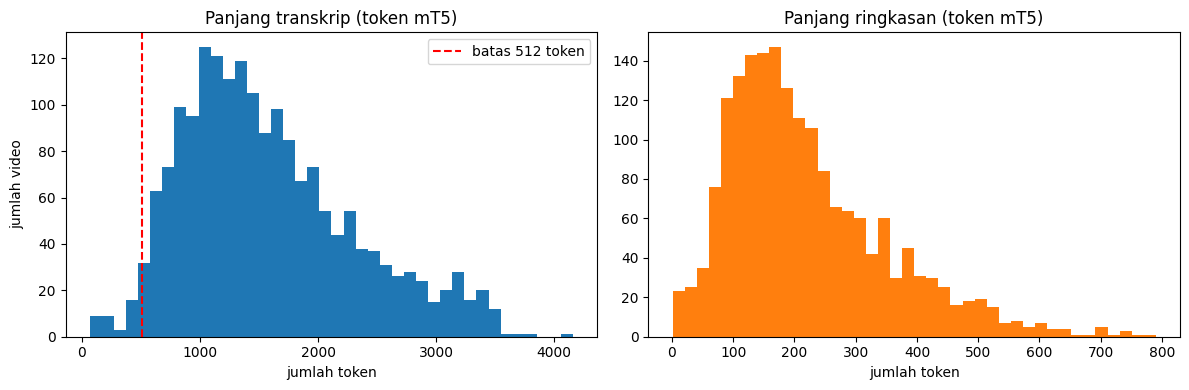

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(data_panjang['token_transkrip'], bins=40)
axes[0].axvline(512, color='red', linestyle='--', label='batas 512 token')
axes[0].set_title('Panjang transkrip (token mT5)')
axes[0].set_xlabel('jumlah token')
axes[0].set_ylabel('jumlah video')
axes[0].legend()

axes[1].hist(data_panjang['token_ringkasan'], bins=40, color='tab:orange')
axes[1].set_title('Panjang ringkasan (token mT5)')
axes[1].set_xlabel('jumlah token')

plt.tight_layout()
plt.savefig(f'{output_tahap1}/distribusi_panjang.png', dpi=150)
plt.show()

### 4.2 Anomali panjang
Dua jenis: ringkasan yang terlalu pendek (< 20 kata) dan ringkasan yang lebih panjang dari transkripnya.

In [ ]:
ringkasan_terlalu_pendek = data_panjang[data_panjang['kata_ringkasan'] < 20]
print('Ringkasan < 20 kata:', len(ringkasan_terlalu_pendek))
ringkasan_terlalu_pendek.sort_values('kata_ringkasan')[['Video Name', 'kata_transkrip', 'kata_ringkasan', kolom_ringkasan]].head(20)

Ringkasan < 20 kata: 42


,Video Name,kata_transkrip,kata_ringkasan,Summary
475,Mechanism of E2 Reaction,624,1,test
455,Ethers,799,7,"In this lecture, I discuss ether compounds."
473,Zaitsev Elimination,804,7,"In this lecture, I discuss Zaitsev's Rule."
480,Transition State,1653,8,"In this lecture, I discuss the transition state."
1000,Pyrimidine Synthesis,972,8,This lecture will discuss the synthesis of pyr...
450,Acidity of Alcohols,529,9,"In this lecture, I discuss the acidity of alco..."
447,Organometallic Reagents,845,10,"In this lecture, I give an introduction to org..."
448,Nomenclature of Alcohols,1227,10,"In this lecture, I show you how to name alcohols."
454,Basicity of Amines,1176,10,"In this lecture, I discuss the basic propertie..."
467,Effect of Nucleophile on Sn1 Reaction,796,11,"In this lecture, I discuss how the nucleophile..."


In [ ]:
ringkasan_lebih_panjang = data_panjang[data_panjang['kompresi_kata'] > 1]
print('Ringkasan lebih panjang dari transkrip:', len(ringkasan_lebih_panjang))
ringkasan_lebih_panjang.sort_values('kompresi_kata', ascending=False)[['Video Name', 'kata_transkrip', 'kata_ringkasan', kolom_transkrip]].head(10)

Ringkasan lebih panjang dari transkrip: 21


,Video Name,kata_transkrip,kata_ringkasan,Transcript
839,Structure of ATCase (Part II),49,286,and what that means is because we have more t...
709,Properties of Water and Hydrophobic Effect (Pa...,79,335,around the nonpolar substance and allows them...
718,Biological Buffer Systems (Part II),69,287,basically remain. And that's exactly why we u...
923,Gluconeogenesis (Steps 3-10) - Part II,103,278,So it's so in phosphate molecules. So we see ...
905,Stage 2 of Glycolysis (Part II),64,162,"is into steps. First, this step takes place a..."
234,Blood Clotting Cascade (Part II),152,380,"with factor 10, it activates factor 8 to comb..."
18,ABO Blood Types (Part II),163,339,"And so does IB, lower case IO. Now, what abou..."
726,Primary Structure of Proteins (Part II),141,281,those rotations will actually lead to stair h...
842,Covalent Modification and Phosphorylation (Par...,97,193,So it amplifies the effects and amplifies the...
781,Sanger Sequencing of DNA (Part II),245,441,of nucleotides following the primer. So we ha...


## 5. Uji terjemahan EN→ID (3 model kandidat)

Kandidat: `Helsinki-NLP/opus-mt-en-id`, `facebook/m2m100_418M`, `facebook/nllb-200-distilled-600M`.
Diterjemahkan **per kalimat** karena model dilatih pada kalimat pendek. Untuk uji cepat, transkrip diambil 15 kalimat pertama saja.

### 5.1 Cek panjang kalimat
Transkrip berasal dari ucapan lisan, jadi ada kalimat yang sangat panjang tanpa titik. Kalimat yang melebihi 256 token akan **terpotong diam-diam** saat diterjemahkan, jadi perlu dicek dulu berapa banyak.

In [ ]:
def pecah_kalimat(teks):
    return [kalimat for kalimat in re.split(r'(?<=[.!?])\s+', str(teks).strip()) if kalimat]

tokenizer_opus = AutoTokenizer.from_pretrained('Helsinki-NLP/opus-mt-en-id')

semua_kalimat = [kalimat for teks in data_panjang[kolom_transkrip] for kalimat in pecah_kalimat(teks)]
panjang_kalimat = pd.Series([len(ids) for ids in tokenizer_opus(semua_kalimat)['input_ids']])

print('Jumlah kalimat:', len(semua_kalimat))
print(panjang_kalimat.describe(percentiles=[.5, .95, .99]).round(1))
print(f'Kalimat > 256 token: {(panjang_kalimat > 256).sum()} ({(panjang_kalimat > 256).mean() * 100:.2f}%)')
print('\nContoh kalimat terpanjang (300 karakter awal):')
print(semua_kalimat[panjang_kalimat.idxmax()][:300])

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/796k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/801k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.26M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (809 > 512). Running this sequence through the model will result in indexing errors


Jumlah kalimat: 99292
count    99292.0
mean        26.4
std         23.9
min          2.0
50%         23.0
95%         54.0
99%         78.0
max       1675.0
dtype: float64
Kalimat > 256 token: 56 (0.06%)

Contoh kalimat terpanjang (300 karakter awal):
So in step number one in order to promote and increase the specificity of the reaction and decrease the number of unwanted products from actually forming we have to use these different types of molecules to direct the correct synthesis of the protein because remember in any given amino acid we have 


### 5.2 Fungsi terjemahan
m2m100 dan NLLB perlu diberi tahu bahasa asal dan tujuan; opus-mt tidak perlu karena memang khusus EN→ID.

In [ ]:
import torch
from transformers import AutoModelForSeq2SeqLM

device = 'cuda' if torch.cuda.is_available() else 'cpu'

kandidat_model_terjemahan = {
    'opusmt': 'Helsinki-NLP/opus-mt-en-id',
    'm2m100': 'facebook/m2m100_418M',
    'nllb': 'facebook/nllb-200-distilled-600M',
}

def muat_model_terjemahan(nama_model):
    tokenizer = AutoTokenizer.from_pretrained(nama_model)
    model = AutoModelForSeq2SeqLM.from_pretrained(nama_model).to(device).eval()
    pengaturan_bahasa = {}
    if 'm2m100' in nama_model:
        tokenizer.src_lang = 'en'
        pengaturan_bahasa['forced_bos_token_id'] = tokenizer.get_lang_id('id')
    elif 'nllb' in nama_model:
        tokenizer.src_lang = 'eng_Latn'
        pengaturan_bahasa['forced_bos_token_id'] = tokenizer.convert_tokens_to_ids('ind_Latn')
    return tokenizer, model, pengaturan_bahasa

@torch.no_grad()
def terjemahkan(daftar_kalimat, tokenizer, model, pengaturan_bahasa, ukuran_batch=32):
    hasil = []
    for i in range(0, len(daftar_kalimat), ukuran_batch):
        batch = tokenizer(daftar_kalimat[i:i + ukuran_batch], return_tensors='pt',
                          padding=True, truncation=True, max_length=256).to(device)
        # pakai max_length saja (bukan max_new_tokens) supaya tidak muncul warning berulang
        keluaran = model.generate(**batch, num_beams=4, max_length=256, **pengaturan_bahasa)
        hasil += tokenizer.batch_decode(keluaran, skip_special_tokens=True)
    return hasil

### 5.3 Jalankan pada sampel yang sama untuk ketiga model
Hasil diurutkan per sampel, jadi di spreadsheet tiga terjemahan dari teks yang sama letaknya berdekatan dan mudah dibandingkan.

In [ ]:
jumlah_sampel = 60
jumlah_kalimat_transkrip = 15
sampel = data_panjang.sample(jumlah_sampel, random_state=42)

semua_hasil = []
for nama_singkat, nama_model in kandidat_model_terjemahan.items():
    tokenizer, model, pengaturan_bahasa = muat_model_terjemahan(nama_model)
    for indeks, baris in sampel.iterrows():
        kalimat_transkrip = pecah_kalimat(baris[kolom_transkrip])[:jumlah_kalimat_transkrip]
        kalimat_ringkasan = pecah_kalimat(baris[kolom_ringkasan])
        semua_hasil.append({
            'idx': indeks,
            'model': nama_singkat,
            'transkrip_en': ' '.join(kalimat_transkrip),
            'transkrip_id': ' '.join(terjemahkan(kalimat_transkrip, tokenizer, model, pengaturan_bahasa)),
            'ringkasan_en': baris[kolom_ringkasan],
            'ringkasan_id': ' '.join(terjemahkan(kalimat_ringkasan, tokenizer, model, pengaturan_bahasa)),
        })
    del model
    torch.cuda.empty_cache()
    print('Selesai:', nama_singkat)

hasil_terjemahan = pd.DataFrame(semua_hasil).sort_values(['idx', 'model']).reset_index(drop=True)
for kolom_isian in ['skor_makna', 'skor_istilah', 'skor_kealamian', 'catatan']:
    hasil_terjemahan[kolom_isian] = ''   # diisi manual, skala 1-3
hasil_terjemahan.to_csv(f'{output_tahap1}/uji_terjemahan_3model.csv', index=False)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  291MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  291MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

... (24 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Selesai: nllb


In [ ]:
# Lihat satu contoh ringkasan dari ketiga model berdampingan
contoh_idx = hasil_terjemahan['idx'].iloc[0]
print('[EN]', hasil_terjemahan.loc[hasil_terjemahan['idx'] == contoh_idx, 'ringkasan_en'].iloc[0][:400], '\n')
for _, baris in hasil_terjemahan[hasil_terjemahan['idx'] == contoh_idx].iterrows():
    print(f"[{baris['model']}] {baris['ringkasan_id'][:400]}\n")

[EN] Bacterial cells do not undergo meiosis but rather an asexual reproduction process known as binary fission. Binary fission produces two identical daughter cells, which implies that there is no genetic recombination taking place in binary fission. Instead, the bacterial cells depend on three different processes to recombine their genetic information. These processes are conjugation, transformation a 

[m2m100] Sel-sel bakteri tidak mengalami meiosis tetapi proses reproduksi asexual yang dikenal sebagai fisi biner. Fisi biner menghasilkan dua sel anak yang identik, yang berarti tidak ada rekombinasi genetik yang terjadi dalam fisi biner. Sebaliknya, sel-sel bakteri bergantung pada tiga proses yang berbeda untuk menggabungkan informasi genetik mereka. Proses ini adalah konjugasi, transformasi dan transduk

[nllb] Sel bakteri tidak mengalami meiosis melainkan proses reproduksi aseksual yang dikenal sebagai fisi biner. Fisi biner menghasilkan dua sel putri yang identik, yang berarti bah

In [ ]:
hasil = pd.read_csv(f'{output_tahap1}/uji_terjemahan_3model.csv')
kata_melayu = r'\b(sahaja|nombor|kapilari|sebaik|kerana|daripada pada)\b'
kata_inggris = r'\b(the|of|and|which|that|is|are)\b'

cek = hasil.assign(
    artefak_spasi = hasil['ringkasan_id'].str.count(r'\w - \w') + hasil['transkrip_id'].str.count(r'\w - \w'),
    kata_melayu   = hasil['ringkasan_id'].str.count(kata_melayu, flags=re.I) + hasil['transkrip_id'].str.count(kata_melayu, flags=re.I),
    sisa_inggris  = hasil['ringkasan_id'].str.count(kata_inggris, flags=re.I) + hasil['transkrip_id'].str.count(kata_inggris, flags=re.I),
    rasio_panjang = hasil['ringkasan_id'].str.split().str.len() / hasil['ringkasan_en'].str.split().str.len(),
)
cek.groupby('model')[['artefak_spasi', 'kata_melayu', 'sisa_inggris', 'rasio_panjang']].agg(['sum', 'mean']).round(2)

artefak_spasi       kata_melayu       sisa_inggris       rasio_panjang  \
                 sum  mean         sum  mean          sum  mean           sum   
model                                                                           
m2m100             4  0.07          16  0.27            1  0.02         50.71   
nllb               4  0.07           0  0.00            1  0.02         50.08   
opusmt            37  0.62           0  0.00            6  0.10         50.63   

              
        mean  
model         
m2m100  0.85  
nllb    0.83  
opusmt  0.84

# Tahap 2: Cleaning & split

In [ ]:
data_bersih = pd.read_csv(csv_path).drop(columns=['Unnamed: 0'])
riwayat_cleaning = [('Data awal', len(data_bersih))]

# 1) Normalisasi spasi: hapus spasi ganda, tab, newline, spasi di awal/akhir
def rapikan_spasi(teks):
    return re.sub(r'\s+', ' ', str(teks)).strip()

for kolom in [kolom_transkrip, kolom_ringkasan]:
    data_bersih[kolom] = data_bersih[kolom].where(data_bersih[kolom].isna(), data_bersih[kolom].map(rapikan_spasi))

# 2) Buang transkrip / ringkasan kosong
data_bersih = data_bersih[data_bersih[kolom_transkrip].notna() & data_bersih[kolom_ringkasan].notna()
                          & (data_bersih[kolom_transkrip] != '') & (data_bersih[kolom_ringkasan] != '')]
riwayat_cleaning.append(('Buang kosong', len(data_bersih)))

# 3) Buang anomali: ringkasan < 20 kata ATAU ringkasan lebih panjang dari transkrip
data_bersih['kata_transkrip'] = data_bersih[kolom_transkrip].str.split().str.len()
data_bersih['kata_ringkasan'] = data_bersih[kolom_ringkasan].str.split().str.len()
data_bersih['kompresi'] = data_bersih['kata_ringkasan'] / data_bersih['kata_transkrip']
data_bersih = data_bersih[(data_bersih['kata_ringkasan'] >= 20) & (data_bersih['kompresi'] <= 1)]
riwayat_cleaning.append(('Buang anomali (ringkasan <20 kata / kompresi >1)', len(data_bersih)))

# 4) Buang SEMUA baris yang ringkasannya duplikat (tidak bisa dipastikan mana yang benar)
data_bersih = data_bersih[~data_bersih[kolom_ringkasan].duplicated(keep=False)]
riwayat_cleaning.append(('Buang ringkasan duplikat', len(data_bersih)))

# 5) Buang transkrip duplikat (jaga-jaga, harusnya 0)
data_bersih = data_bersih[~data_bersih[kolom_transkrip].duplicated(keep=False)]
riwayat_cleaning.append(('Buang transkrip duplikat', len(data_bersih)))

# 6) Grup topik: judul tanpa "(Part I)", "(Part II)", "Part 2", dst.
#    Part I dan Part II dari topik yang sama harus masuk split yang sama
def buat_grup_topik(baris):
    nama_video = re.sub(r'[\s\-–:,]*\(?\bpart\s+([ivx]+|\d+)\b\)?\s*$', '', baris['Video Name'], flags=re.I)
    return f"{baris['Course Name']} | {baris['Chapter']} | {nama_video.strip().lower()}"

data_bersih['grup_topik'] = data_bersih.apply(buat_grup_topik, axis=1)
data_bersih = data_bersih.reset_index(drop=True)

print(pd.DataFrame(riwayat_cleaning, columns=['Langkah', 'Sisa baris']).to_string(index=False))
print('\nJumlah grup topik:', data_bersih['grup_topik'].nunique())

                                         Langkah  Sisa baris
                                       Data awal        1871
                                    Buang kosong        1842
Buang anomali (ringkasan <20 kata / kompresi >1)        1779
                        Buang ringkasan duplikat        1729
                        Buang transkrip duplikat        1729

Jumlah grup topik: 1721


In [ ]:
# Cek: grup yang berisi lebih dari 1 video (Part I/II yang tergabung)
grup_multi_video = data_bersih.groupby('grup_topik')['Video Name'].apply(list)
grup_multi_video = grup_multi_video[grup_multi_video.str.len() > 1]
print('Grup berisi >1 video:', len(grup_multi_video))
display(grup_multi_video.head(10))

# Cek filler lisan (cuma dihitung, BELUM dibuang)
jumlah_filler = data_bersih[kolom_transkrip].str.count(r'\b(um+|uh+|erm)\b', flags=re.I)
print('Transkrip yang mengandung filler:', (jumlah_filler > 0).sum(),
      '| rata-rata per transkrip:', round(jumlah_filler.mean(), 2))
print(data_bersih[['kata_transkrip', 'kata_ringkasan', 'kompresi']].describe().round(2))

Grup berisi >1 video: 5


,Video Name
grup_topik,
Classical physics | Wave Motion | doppler effect for sound waves,"[Doppler Effect for Sound Waves (Part I), Dopp..."
General chemistry | Kinetic Molecular Theory and Chemical Reactions | rate determining step and rate law,"[Rate Determining Step and Rate Law - Part I, ..."
Organic chemistry | Addition Reactions | hydroboration reaction,"[Hydroboration Reaction - Part I, Hydroboratio..."
Organic chemistry | Addition Reactions | synthesis of alcohols examples,"[Synthesis of Alcohols Examples (Part I), Synt..."
Organic chemistry | Peptide Chemistry | determining protein structure,"[Determining Protein Structure (Part I), Deter..."


Transkrip yang mengandung filler: 7 | rata-rata per transkrip: 0.0
       kata_transkrip  kata_ringkasan  kompresi
count         1729.00         1729.00   1729.00
mean          1090.56          145.33      0.15
std            460.70           78.21      0.08
min            254.00           21.00      0.02
25%            737.00           87.00      0.09
50%           1017.00          130.00      0.13
75%           1373.00          188.00      0.19
max           3047.00          480.00      0.64


## Split 80/10/10 per grup topik

Setiap baris di dataset adalah video yang berbeda, jadi split "per video" sama saja dengan split per baris. Yang perlu dijaga adalah video **Part I / Part II** dari topik yang sama, karena isinya mirip. Karena itu split dilakukan per `grup_topik` dengan seed tetap.

`GroupShuffleSplit` membagi berdasarkan jumlah grup, bukan jumlah baris, jadi proporsinya bisa sedikit meleset dari 80/10/10.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

seed = 42

# Tahap 1: 80% train, 20% sisa
pemisah_pertama = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
indeks_train, indeks_sisa = next(pemisah_pertama.split(data_bersih, groups=data_bersih['grup_topik']))
data_sisa = data_bersih.iloc[indeks_sisa]

# Tahap 2: 20% sisa dibagi dua -> 10% val, 10% test
pemisah_kedua = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=seed)
indeks_dev, indeks_test = next(pemisah_kedua.split(data_sisa, groups=data_sisa['grup_topik']))

data_bersih['split'] = 'train'
data_bersih.loc[data_sisa.index[indeks_dev], 'split'] = 'val'
data_bersih.loc[data_sisa.index[indeks_test], 'split'] = 'test'

print(data_bersih['split'].value_counts())
print((data_bersih['split'].value_counts(normalize=True) * 100).round(1))

split
train    1384
test      173
val       172
Name: count, dtype: int64
split
train    80.0
test     10.0
val       9.9
Name: proportion, dtype: float64


In [ ]:
# Bukti tidak ada kebocoran: tidak ada grup topik yang muncul di dua split
grup_per_split = {nama: set(data_bersih.loc[data_bersih['split'] == nama, 'grup_topik']) for nama in ['train', 'val', 'test']}
print('Irisan train-val :', len(grup_per_split['train'] & grup_per_split['val']))
print('Irisan train-test:', len(grup_per_split['train'] & grup_per_split['test']))
print('Irisan val-test  :', len(grup_per_split['val'] & grup_per_split['test']))

# Sebaran course per split (persen), supaya tiap split tidak didominasi satu course
display((pd.crosstab(data_bersih['Course Name'], data_bersih['split'], normalize='columns') * 100).round(1))

data_bersih.to_csv(f'{output_tahap2}/data_clean_en.csv', index=False)
print('Tersimpan:', f'{output_tahap2}/data_clean_en.csv')

Irisan train-val : 0
Irisan train-test: 0
Irisan val-test  : 0


split,test,train,val
Course Name,,,
Biochemistry,12.1,13.9,12.2
Biology,16.2,12.9,15.1
Classical physics,34.1,36.5,37.2
General chemistry,9.2,7.7,5.2
Modern physics,15.0,12.9,14.0
Organic chemistry,13.3,16.2,16.3


Tersimpan: /content/drive/MyDrive/DEEP_LEARNING_test/tahap2/data_clean_en.csv
